# Malahy (1985) finite-element pipelay model — Python implementation (3-D)

Implementation of the method in R. C. Malahy Jr., *A Nonlinear Finite Element Method for the Analysis of the Offshore Pipelaying Problem*, Rice University Ph.D. thesis, 1985 (ProQuest 8517222), run on the thesis example problem (Table 5-1: 16-inch pipe, 240 ft of water) as a full **3-D** analysis (6 DOF per node, 6-DOF barge motion).

**What the method is (thesis chapter → code):**

| Thesis | What | Where here |
|---|---|---|
| §2.1–2.3, Eq. 2-4/2-5 | residual force vector `F = Σ f_i + Σ G_j`, element end forces rotated to global axes | `Model.residual`, end of `pipe_element` |
| §2.6–2.7, App. A | 6 DOF/node (X,Y,Z + Euler angles ψ,α,β); element frame on the chord; end rotations θ₁,θ₂,φ₁,φ₂ and twist from direction-cosine matrices | `node_axes`, `elem_axes`, `pipe_element` |
| §2.12, Eq. 2-49/2-51 | deformation forces with **beam-column coupling** (bowing shortening in the axial strain) | `pipe_element` |
| §2.13, Eq. 2-54 | weight, buoyancy by submerged fraction | `pipe_element` |
| §2.15, Eq. 2-58 | consistent-mass inertial forces (pipe + added mass) | `pipe_element` (`mass4`) |
| §2.16, Eq. 2-63…2-68 | Morison drag, 5-point Gauss quadrature | `pipe_element` |
| §2.4, 2.10, Eq. 2-35…2-38 | trapezoidal rule with sub-intervals h₁ ≤ h₂ (numerical damping ratio h₂/(h₁+h₂)) | `integrate` |
| §3.1 | Newton–Raphson on the residual | `Model.newton` |
| §4.3 | pipe-support rollers as (unilateral) springs | `Model.node_loads` |
| §4.4 | tensioner (axial spring about a nominal tension) | `Model.node_loads` |
| §4.5 | seabed vertical soil spring, axial fixity of the last node | `Model.node_loads`, `Model.__init__` |

**Deviations you should know about (all deliberate):**
1. **Tangent matrix.** The thesis derives analytic stiffness/mass/damping matrices (Ch. 3). Here the tangent is an element-wise central-difference Jacobian of the *same* residual, so the converged solution is the same; only the Newton path and speed differ.
2. **Stinger.** The thesis models it with lumped beam elements (hinge at the hitch, ballast, buoyancy). Here the stinger is a *rigid* roller bed (arc of radius 700 ft) that moves with the barge. A flexible stinger would be extra elements using the same `pipe_element` with the undeformed-rotation matrix of Eq. 4-5/4-6.
3. **3-D analysis.** All six DOF per node (X, Y, Z, ψ, α, β) are free. Rigid-body modes are restrained as follows: the tensioner end (node 0) follows the barge (twist and heading prescribed from barge roll and yaw, lateral position held by a stiff spring); the seabed end is anchored; the rollers have flanged guides (5·10⁶ N/m, active only while the pipe bears on the roller); a lateral soil spring (10⁵ N/m) acts where the pipe lies on the seabed. The barge + stinger move as a rigid body with all six motions (surge, sway, heave, roll, pitch, yaw) from the Table 5-1 response operators; the 135° wave heading is taken to be already contained in them. `planar=True` in `Model` restores the vertical-plane problem.
4. **Sign convention for θ, φ.** I use θ = e_y·n_x, φ = e_z·n_x (slope of the node tangent relative to the chord), which makes Eq. 2-51 hold with its printed signs. The Appendix B listing evaluates the same dot products with the opposite sign; the signs here were chosen so that the end forces satisfy `f = −∂U/∂q`.
5. **Axial strain base.** As in the Appendix B listing, strain is `L/L₀ + bow − 1`, and the stress-free length `L₀` of each element is set so the starting shape carries no axial strain.
6. **Inertia.** Consistent mass matrices as in Eq. 2-58, without the small chord-rotation coupling terms; centripetal/Coriolis terms neglected (as in the thesis).
7. **Rollers.** Reaction acts along the normal of the roller line (the thesis uses the mutual perpendicular of pipe and roller, which differs by the small pipe–roller angle). Normal contact is a smoothed unilateral spring, `K = 2·10⁷ N/m`; with much stiffer rollers the contact period becomes comparable to the 0.1 s step and the integration chatters.
8. **Assumed values not in the thesis:** drag coefficient 1.0, added-mass coefficient 1.0, steel E = 207 GPa, tensioner stiffness 5·10⁴ N/m, response-operator **phases** (heave and sway/roll: sine; surge and pitch 90° behind, yaw 90° ahead), the barge rotation reference point (3rd barge support, at the waterline), roller-guide and lateral-soil stiffnesses, ≈ 12 m elements in the free span, 150 ft of seabed.

SI units internally (1 ft = 0.3048 m, 1 kip = 4448.2 N).

In [1]:
import numpy as np, scipy.linalg
import matplotlib.pyplot as plt

FT, LBF, KIP = 0.3048, 4.4482216, 4448.2216      # ft->m, lbf->N, kip->N
G_ACC, RHO_W = 9.81, 1025.0

# ---------------------------------------------------------------- Appendix A
def node_axes(psi, alpha, beta):
    """Eq. A-3. Columns = nodal x,y,z axes in global components."""
    ca, sa, cb, sb, cp, sp = np.cos(alpha), np.sin(alpha), np.cos(beta), np.sin(beta), np.cos(psi), np.sin(psi)
    return np.array([
        [cb*ca, -ca*sb*cp - sa*sp,  ca*sb*sp - sa*cp],
        [sb,     cb*cp,            -cb*sp           ],
        [cb*sa,  ca*sp - sa*sb*cp,  sa*sb*sp + ca*cp]])

def elem_axes(cx, psi=0.0):
    """Eq. A-1 (chord direction cosines cx, twist psi about chord). Columns = element x,y,z axes."""
    Cxx, Cyx, Czx = cx
    B = np.hypot(Cxx, Czx)
    cp, sp = np.cos(psi), np.sin(psi)
    if B < 1e-9:                       # chord parallel to global Y: alternative definition
        s = np.sign(Cyx) if Cyx != 0 else 1.0
        return np.array([[0.0, -s, 0.0], [s, 0.0, 0.0], [0.0, 0.0, 1.0]])
    return np.array([
        [Cxx, -(Cxx*Cyx*cp + Czx*sp)/B, (Cxx*Cyx*sp - Czx*cp)/B],
        [Cyx,  B*cp,                    -B*sp                  ],
        [Czx,  (Cxx*sp - Czx*Cyx*cp)/B, (Czx*Cyx*sp + Cxx*cp)/B]])

def euler_rates_to_omega(alpha, beta, psi, ad, bd, pd, add=0., bdd=0., pdd=0.):
    """Eq. 2-31/2-32 (centripetal and Coriolis terms neglected as in the thesis).
    Angular velocity / acceleration about global X,Y,Z for the Euler set (psi, alpha, beta)."""
    ca, sa, cb, sb = np.cos(alpha), np.sin(alpha), np.cos(beta), np.sin(beta)
    f = lambda p, a, b: np.array([p*cb*ca - b*sa, p*sb - a, p*cb*sa + b*ca])   # alpha is a rotation about -Y
    return f(pd, ad, bd), f(pdd, add, bdd)


## Pipe properties (Table 5-1) and the beam element

Element end forces = deformation (Eq. 2-51) + weight (2-54) + inertia (2-58) + drag (2-63), evaluated in the element frame whose x axis is the chord, then rotated to global axes (Eq. 2-5).

In [2]:
# ---------------------------------------------------------------- pipe data
class Pipe:
    def __init__(s, D_steel=16*0.0254, t=0.5*0.0254, t_coat=2*0.0254, E=207e9, G=79.3e9,
                 w_air=191.6*LBF/FT, w_sub=52.0*LBF/FT, Cd=1.0, Ca=1.0):
        s.D_steel, s.t = D_steel, t
        s.D_out = D_steel + 2*t_coat                      # hydrodynamic diameter
        d_in = D_steel - 2*t
        s.EA = E*np.pi/4*(D_steel**2 - d_in**2)
        s.EI = E*np.pi/64*(D_steel**4 - d_in**4)
        s.GJ = G*np.pi/32*(D_steel**4 - d_in**4)
        s.w_air, s.w_sub = w_air, w_sub
        s.m_pipe = w_air/G_ACC
        s.m_eff = s.m_pipe + Ca*RHO_W*np.pi/4*s.D_out**2   # Eq. 2-55 added mass
        s.Cd = Cd
        s.E = E

GP = np.array([0.04691008, 0.23076534, 0.5, 0.76923466, 0.95308992])   # Table 2-1
GW = np.array([0.11846344, 0.23931434, 0.28444444, 0.23931434, 0.11846344])

def hermite(xi, L):
    return np.array([1-3*xi**2+2*xi**3, L*(xi-2*xi**2+xi**3), 3*xi**2-2*xi**3, L*(-xi**2+xi**3)])

def mass4(m, L):
    return m*L/420*np.array([[156, 22*L, 54, -13*L], [22*L, 4*L**2, 13*L, -3*L**2],
                             [54, 13*L, 156, -22*L], [-13*L, -3*L**2, -22*L, 4*L**2]])


In [3]:
# ---------------------------------------------------------------- pipe element
def pipe_element(Xe, Ve, Ae, L0, pipe, y_water, dynamic):
    """End forces on the 2 nodes (global components, 12 values) = Eq. 2-41 contributions:
       deformation (2-51) + weight (2-54) + inertia (2-58) + drag (2-63).
       Xe/Ve/Ae: [X,Y,Z,psi,alpha,beta] x 2 nodes (positions, velocities, accelerations)."""
    p1, p2 = Xe[:3], Xe[6:9]
    d = p2 - p1; L = np.linalg.norm(d)
    Ce = elem_axes(d/L)
    Cn1, Cn2 = node_axes(*Xe[3:6]), node_axes(*Xe[9:12])
    # element end-node rotations relative to the chord (section 2.7)
    th1 = np.arctan2(Ce[:, 1]@Cn1[:, 0], Ce[:, 0]@Cn1[:, 0]); th2 = np.arctan2(Ce[:, 1]@Cn2[:, 0], Ce[:, 0]@Cn2[:, 0])
    ph1 = np.arctan2(Ce[:, 2]@Cn1[:, 0], Ce[:, 0]@Cn1[:, 0]); ph2 = np.arctan2(Ce[:, 2]@Cn2[:, 0], Ce[:, 0]@Cn2[:, 0])
    dps = Cn1[:, 2]@Cn2[:, 1]
    EA, EI, GJ = pipe.EA, pipe.EI, pipe.GJ
    # ---- deformation forces, Eq. 2-51 (beam-column coupling through bowing shortening)
    bow = ((2*th1-th2)*th1 + 2*th2**2 + (2*ph1-ph2)*ph1 + 2*ph2**2)/30.0
    T = EA*(L/L0 + bow - 1.0)
    TL = T*L0
    f = np.zeros(12)
    f[0] = T;  f[6] = -T
    f[5]  = -2*EI/L0*(2*th1+th2) - TL*(4*th1-th2)/30
    f[11] = -2*EI/L0*(th1+2*th2) - TL*(4*th2-th1)/30
    f[1] = (f[5]+f[11])/L;  f[7] = -f[1]
    f[3] = GJ/L0*dps;       f[9] = -f[3]
    f[4]  =  2*EI/L0*(2*ph1+ph2) + TL*(4*ph1-ph2)/30
    f[10] =  2*EI/L0*(2*ph2+ph1) + TL*(4*ph2-ph1)/30
    f[2] = -(f[4]+f[10])/L;  f[8] = -f[2]
    # ---- weight, Eq. 2-54 (fraction submerged from the nodal heights)
    yy1, yy2 = p1[1]-y_water, p2[1]-y_water
    if yy1 <= 0 and yy2 <= 0: sub = 1.0
    elif yy1 > 0 and yy2 > 0: sub = 0.0
    else: sub = (-min(yy1, yy2))/abs(yy1-yy2)
    w = (1-sub)*pipe.w_air + sub*pipe.w_sub
    Q = -w*Ce[1, :]                       # gravity (0,-w,0) in element axes: Qx,Qy,Qz
    Qx, Qy, Qz = Q
    dth, dph = th1-th2, ph1-ph2
    f[0] += Qx*L0/2 - Qy*L0*dth/12 - Qz*L0*dph/12
    f[1] += Qy*L0/2 + Qx*L0*dth/12
    f[2] += Qz*L0/2 + Qx*L0*dph/12
    f[4] += -Qz*L0*L/12;  f[5] += Qy*L0*L/12
    f[6] += Qx*L0/2 + Qy*L0*dth/12 + Qz*L0*dph/12
    f[7] += Qy*L0/2 - Qx*L0*dth/12
    f[8] += Qz*L0/2 - Qx*L0*dph/12
    f[10] += Qz*L0*L/12;  f[11] += -Qy*L0*L/12
    # ---- inertia (2-58) and drag (2-63) -- dynamic problems only
    if dynamic:
        v1, v2 = Ce.T@Ve[:3], Ce.T@Ve[6:9]
        a1, a2 = Ce.T@Ae[:3], Ce.T@Ae[6:9]
        om1, _ = euler_rates_to_omega(Xe[4], Xe[5], Xe[3], Ve[4], Ve[5], Ve[3])
        om2, _ = euler_rates_to_omega(Xe[10], Xe[11], Xe[9], Ve[10], Ve[11], Ve[9])
        _, al1 = euler_rates_to_omega(Xe[4], Xe[5], Xe[3], Ve[4], Ve[5], Ve[3], Ae[4], Ae[5], Ae[3])
        _, al2 = euler_rates_to_omega(Xe[10], Xe[11], Xe[9], Ve[10], Ve[11], Ve[9], Ae[10], Ae[11], Ae[9])
        om1, om2, al1, al2 = Ce.T@om1, Ce.T@om2, Ce.T@al1, Ce.T@al2
        # transverse DOF sets: plane x-y: (y1, thz1, y2, thz2);  plane x-z: (z1, -thy1, z2, -thy2)
        qy_d = np.array([v1[1], om1[2], v2[1], om2[2]]);  qy_dd = np.array([a1[1], al1[2], a2[1], al2[2]])
        qz_d = np.array([v1[2], -om1[1], v2[2], -om2[1]]); qz_dd = np.array([a1[2], -al1[1], a2[2], -al2[1]])
        M4 = mass4(pipe.m_eff, L0)
        fy, fz = -M4@qy_dd, -M4@qz_dd
        f[0] += -pipe.m_pipe*L0*(a1[0]/3 + a2[0]/6);  f[6] += -pipe.m_pipe*L0*(a1[0]/6 + a2[0]/3)
        # drag by 5-point Gauss quadrature (still water), Eq. 2-65..2-68
        for xi, wg in zip(GP, GW):
            N = hermite(xi, L0)
            vy, vz = N@qy_d, N@qz_d
            vt = np.hypot(vy, vz)
            c = -0.5*RHO_W*pipe.D_out*pipe.Cd*vt*wg*L0
            fy += c*vy*N;  fz += c*vz*N
        f[1] += fy[0]; f[5] += fy[1]; f[7] += fy[2]; f[11] += fy[3]
        f[2] += fz[0]; f[4] += -fz[1]; f[8] += fz[2]; f[10] += -fz[3]
    # ---- rotate to global axes (Eq. 2-5)
    out = np.empty(12)
    out[0:3] = Ce@f[0:3];  out[3:6] = Ce@f[3:6]
    out[6:9] = Ce@f[6:9];  out[9:12] = Ce@f[9:12]
    return out


## Boundary elements, assembly, Newton–Raphson

`Model.residual` assembles Eq. 2-4; `Model.newton` is the damped Newton iteration of §3.1 (back-tracking line search on the residual norm).

In [4]:
# ---------------------------------------------------------------- model / boundary elements
def rot(w):
    """Rotation matrix for the rotation vector w (Rodrigues)."""
    th = np.linalg.norm(w)
    K = np.array([[0, -w[2], w[1]], [w[2], 0, -w[0]], [-w[1], w[0], 0]])
    if th < 1e-12: return np.eye(3) + K
    return np.eye(3) + np.sin(th)/th*K + (1-np.cos(th))/th**2*(K@K)

class Model:
    """Pipeline from the tensioner (node 0) to the seabed (node N-1). Global X along the pipeline, Y up, Z lateral.
       planar=False : all 6 DOF/node free (3-D analysis).  planar=True: unknowns X, Y, beta only (vertical plane)."""
    def __init__(s, pipe, nodes_xyb, supports, y_water, y_bed, T0, K_roll=5e7, K_soil=2e6, K_t=5e4,
                 planar=False, K_guide=5e6, K_soil_lat=1e5):
        s.pipe = pipe; s.N = len(nodes_xyb); s.planar = planar
        s.X0 = np.zeros((s.N, 6)); s.X0[:, 0] = nodes_xyb[:, 0]; s.X0[:, 1] = nodes_xyb[:, 1]; s.X0[:, 5] = nodes_xyb[:, 2]
        d = np.diff(s.X0[:, :3], axis=0); L = np.linalg.norm(d, axis=1)
        # stress-free length = chord + bowing shortening of the starting shape (Eq. 2-46/2-47),
        # so that the starting shape carries no spurious axial strain
        s.L0 = L.copy()
        for e in range(s.N-1):
            Ce = elem_axes(d[e]/L[e]); b = []
            for j in (e, e+1):
                n = node_axes(*s.X0[j, 3:6])[:, 0]; b.append(np.arctan2(Ce[:, 1]@n, Ce[:, 0]@n))
            s.L0[e] = L[e]*(1 + ((2*b[0]-b[1])*b[0] + 2*b[1]**2)/30.0)
        s.supports = supports                      # node -> (x, y, nx, ny): support point of the pipe centreline, normal of the roller line
        s.y_water, s.y_bed, s.T0, s.K_roll, s.K_soil, s.K_t = y_water, y_bed, T0, K_roll, K_soil, K_t
        s.K_guide, s.K_soil_lat = K_guide, K_soil_lat
        s.x0_ref = s.X0[0, :3].copy(); s.roll_eps = 1e-3
        s.c_rot = np.array([supports[2][0], y_water, 0.0])     # barge motion reference point (assumed: 3rd barge support, at the waterline)
        mask = np.zeros((s.N, 6), bool)
        if planar:
            mask[:, [0, 1, 5]] = True; mask[-1, [0, 5]] = False
        else:
            mask[:] = True
            mask[0, [3, 4]] = False                # tensioner end: twist and heading follow the barge (prescribed)
            mask[-1, [0, 2, 3, 4, 5]] = False      # seabed end anchored (Y rests on the soil spring)
        s.free = np.flatnonzero(mask.ravel())

    # ---- barge rigid-body pose: off = [u_x,u_y,u_z, w_x,w_y,w_z] (translations, small rotations about X,Y,Z)
    def pose(s, off):
        o = np.zeros(6); o[:len(off)] = off
        return rot(o[3:6]), o[:3], o
    def rigid_point(s, p, R, u):
        return s.c_rot + R@(p - s.c_rot) + u
    def apply_prescribed(s, x, off):
        if not s.planar:
            _, _, o = s.pose(off); x[0, 3] = o[3]; x[0, 4] = -o[4]      # twist = roll, heading alpha = -yaw
        return x

    def contact(s, i, X, R, u):
        """Roller support (4-8..4-12): unilateral, smoothed spring along the roller-line normal + lateral flange guide."""
        sx, sy, nx, ny = s.supports[i]
        P = s.rigid_point(np.array([sx, sy, 0.0]), R, u); n = R@np.array([nx, ny, 0.0]); zh = R@np.array([0.0, 0.0, 1.0])
        d = (X[:3]-P)@n; eps = s.roll_eps
        Rn = s.K_roll*eps*np.logaddexp(0.0, -d/eps); f = Rn*n
        if not s.planar:                                  # guide only acts while the pipe is on the roller
            f = f - s.K_guide*(1-np.exp(-Rn/2e3))*((X[:3]-P)@zh)*zh
        return f, Rn, d

    def roller_state(s, x, off=(0., 0.)):
        R, u, _ = s.pose(off); out = {}
        for i in s.supports:
            _, Rn, d = s.contact(i, x[i], R, u); out[i] = (Rn, d)
        return out

    def tensions(s, x):
        out = []
        for e in range(s.N-1):
            d = x[e+1, :3]-x[e, :3]; L = np.linalg.norm(d); Ce = elem_axes(d/L)
            b = [np.arctan2(Ce[:, 1]@node_axes(*x[j, 3:6])[:, 0], Ce[:, 0]@node_axes(*x[j, 3:6])[:, 0]) for j in (e, e+1)]
            out.append(s.pipe.EA*(L/s.L0[e] + ((2*b[0]-b[1])*b[0] + 2*b[1]**2)/30.0 - 1))
        return np.array(out)

    def node_loads(s, i, x, v, a, off):
        """Boundary elements on node i (Chapter 4): rollers, tensioner (4-15), seabed (4-19)."""
        R, u, _ = s.pose(off)
        g = np.zeros(6); X = x[i]
        if i in s.supports:
            g[:3] += s.contact(i, X, R, u)[0]
        if i == 0:                                # tensioner: nominal tension + axial spring along the barge x axis, lateral hold
            P0 = s.rigid_point(s.x0_ref, R, u); ax = R@np.array([1.0, 0.0, 0.0]); zh = R@np.array([0.0, 0.0, 1.0])
            g[:3] += -(s.T0 + s.K_t*((X[:3]-P0)@ax))*ax
            if not s.planar: g[:3] += -s.K_guide*((X[:3]-P0)@zh)*zh
        if X[1] < s.y_bed:                        # seabed vertical soil reaction
            g[1] += s.K_soil*(s.y_bed - X[1])
        if not s.planar:                          # lateral soil restraint where the pipe lies on the seabed
            g[2] += -s.K_soil_lat*X[2]*scipy.special.expit(-(X[1]-s.y_bed)/0.05)
        return g

    def residual(s, x, v=None, a=None, off=(0., 0.)):
        dyn = v is not None
        if not dyn: v = a = np.zeros_like(x)
        R = np.zeros_like(x)
        for e in range(s.N-1):
            sl = slice(e, e+2)
            R[sl] += pipe_element(x[sl].ravel(), v[sl].ravel(), a[sl].ravel(), s.L0[e], s.pipe, s.y_water, dyn).reshape(2, 6)
        for i in range(s.N):
            R[i] += s.node_loads(i, x, v, a, off)
        return R

    def jacobian(s, x, v=None, a=None, off=(0., 0.), cv=0.0, ca=0.0):
        """Element-wise central-difference tangent (replaces the analytic Chapter 3 matrices).
           cv, ca: d(v)/d(x) and d(a)/d(x) from the time integrator (Eq. 2-37/2-38)."""
        dyn = v is not None
        if not dyn: v = a = np.zeros_like(x)
        n = x.size; J = np.zeros((n, n))
        hs = np.array([1e-6]*3 + [1e-7]*3)
        for e in range(s.N-1):
            sl = slice(e, e+2)
            xe, ve, ae = x[sl].ravel().copy(), v[sl].ravel().copy(), a[sl].ravel().copy()
            Je = np.zeros((12, 12))
            for k in range(12):
                h = hs[k % 6]
                xp, xm = xe.copy(), xe.copy(); xp[k] += h; xm[k] -= h
                vp, vm = ve + cv*(xp-xe), ve + cv*(xm-xe)
                ap, am = ae + ca*(xp-xe), ae + ca*(xm-xe)
                Je[:, k] = (pipe_element(xp, vp, ap, s.L0[e], s.pipe, s.y_water, dyn) -
                            pipe_element(xm, vm, am, s.L0[e], s.pipe, s.y_water, dyn))/(2*h)
            idx = np.r_[e*6:e*6+12]
            J[np.ix_(idx, idx)] += Je
        for i in range(s.N):                 # boundary elements
            for k in range(6):
                h = hs[k]
                xp, xm = x.copy(), x.copy(); xp[i, k] += h; xm[i, k] -= h
                vp, vm = v + cv*(xp-x), v + cv*(xm-x)
                gp = s.node_loads(i, xp, vp, a, off); gm = s.node_loads(i, xm, vm, a, off)
                J[i*6:i*6+6, i*6+k] += (gp-gm)/(2*h)
        return J

    def newton(s, x, v_fun=None, off=(0., 0.), cv=0.0, ca=0.0, tol=1e-3, maxit=40, verbose=False, reuse_J=False):
        """Damped Newton-Raphson (Section 3.1). v_fun(x) -> (v,a) for the dynamic case."""
        x = x.copy(); fr = s.free
        def res(xx):
            if v_fun is None: return s.residual(xx, off=off)
            v, a = v_fun(xx); return s.residual(xx, v, a, off)
        R = res(x); r0 = np.linalg.norm(R.ravel()[fr])
        lu = None
        for it in range(maxit):
            if lu is None or not reuse_J:
                if v_fun is None: J = s.jacobian(x, off=off)
                else:
                    v, a = v_fun(x); J = s.jacobian(x, v, a, off, cv, ca)
                lu = scipy.linalg.lu_factor(J[np.ix_(fr, fr)])
            dx = scipy.linalg.lu_solve(lu, -R.ravel()[fr])
            lam = 1.0
            while True:
                xn = x.copy().ravel(); xn[fr] += lam*dx; xn = xn.reshape(x.shape)
                Rn = res(xn); rn = np.linalg.norm(Rn.ravel()[fr])
                if rn < (1-1e-4*lam)*r0 or lam < 1e-3: break
                lam *= 0.5
            x, R, r0 = xn, Rn, rn
            if verbose: print(it, r0, lam)
            if r0 < tol: return x, True, it+1
        return x, False, maxit


## Time integration

Eq. 2-37/2-38: `ẋⁿ⁺¹ = (xⁿ⁺¹−xⁿ)/h₂ − (h₁/h₂) ẋⁿ`, same form for the acceleration, with `h₁+h₂ = h` and `h₂/(h₁+h₂) = 0.55` (Table 5-1). Barge motion in all six degrees of freedom from the response operators (wave height 6.56 ft → amplitude 1 m, period 10 s), ramped in over the first period. Roll is a rotation about the pipeline axis X, yaw about the vertical Y, pitch about the lateral Z.

In [5]:
# ---------------------------------------------------------------- time integration
def barge_motion(t, a_wave=1.0, T_wave=10.0,
                 rao=dict(surge=0.325, sway=0.350, heave=0.500),            # m/m   (Table 5-1, ft/ft)
                 rao_ang=dict(roll=0.400, pitch=0.500, yaw=0.225),           # deg per ft of wave amplitude
                 phase=dict(surge=-90., sway=0., heave=0., roll=0., pitch=-90., yaw=90.)):   # degrees, ASSUMED
    """Rigid barge+stinger motion [u_x,u_y,u_z, w_x,w_y,w_z] from the response operators (regular wave, 6.56 ft -> amplitude 1 m).
       roll = rotation about X (along the pipeline), yaw = about Y (vertical), pitch = about Z (lateral, in the vertical plane)."""
    w = 2*np.pi/T_wave
    ramp = 0.5*(1-np.cos(np.pi*min(t/T_wave, 1.0)))          # smooth start-up over one wave period
    f = lambda k: np.sin(w*t + np.radians(phase[k]))
    a_ft = a_wave/FT
    lin = [rao['surge']*a_wave*f('surge'), rao['heave']*a_wave*f('heave'), rao['sway']*a_wave*f('sway')]
    ang = [np.radians(rao_ang['roll']*a_ft)*f('roll'), np.radians(rao_ang['yaw']*a_ft)*f('yaw'), np.radians(rao_ang['pitch']*a_ft)*f('pitch')]
    return ramp*np.array(lin + ang)

def barge_motion_planar(t, **kw):
    """Vertical-plane subset (surge, heave, pitch): for checking that the 3-D model stays in-plane."""
    o = barge_motion(t, **kw); o[[2, 3, 4]] = 0.0; return o

def integrate(m, x0, t_end, h=0.1, damping_ratio=0.55, motion=barge_motion, verbose=False):
    """March Eq. 2-7 forward: X^{n+1} from Newton at every step; velocities/accelerations from Eq. 2-37/2-38."""
    h2 = damping_ratio*h; h1 = h - h2
    x, v, a = x0.copy(), np.zeros_like(x0), np.zeros_like(x0)
    nsteps = int(round(t_end/h)); hist = {'t': [0.], 'x': [x.copy()], 'iters': []}
    for n in range(nsteps):
        t = (n+1)*h; off = motion(t)
        xn_, vn_, an_ = x.copy(), v.copy(), a.copy()
        def va(xx):
            vv = (xx - xn_)/h2 - (h1/h2)*vn_            # Eq. 2-37
            aa = (vv - vn_)/h2 - (h1/h2)*an_            # Eq. 2-38
            return vv, aa
        xp = x + h*v                                   # predictor
        xp[-1, [0, 2, 3, 4, 5]] = x[-1, [0, 2, 3, 4, 5]]
        m.apply_prescribed(xp, off)
        xnew, ok, it = m.newton(xp, v_fun=va, off=off, cv=1/h2, ca=1/h2**2, tol=1.0, reuse_J=True, maxit=8)
        if not ok:      # contact changed: fall back to full Newton with a fresh tangent every iteration
            xnew, ok, it = m.newton(m.apply_prescribed(x.copy(), off), v_fun=va, off=off, cv=1/h2, ca=1/h2**2, tol=1.0, reuse_J=False, maxit=40)
        if not ok: print("no convergence at t =", t, "res"); break
        v, a = va(xnew); x = xnew
        hist['t'].append(t); hist['x'].append(x.copy()); hist['iters'].append(it)
        if verbose and n % 10 == 0: print(round(t, 2), it)
    hist['x'] = np.array(hist['x']); hist['t'] = np.array(hist['t'])
    return hist


## Example geometry (Table 5-1)

5 supports on the laybarge arc (R = 750 ft, 40 ft spacing), 8 on the stinger arc (R = 700 ft, 30 ft spacing, 240 ft long), then the free span and seabed. The deck is 24 ft above water (my choice, not in the thesis), which puts the stinger tip about 83 ft below the surface.

In [6]:
from scipy.optimize import brentq

def build(dn_free=12.0, deck_above_water=24*FT, depth=240*FT, T0=40*KIP, **kw):
    Rb, Rs = 750*FT, 700*FT                      # laybarge / stinger pipe-support radii
    sb = np.array([0, 40, 80, 120, 160])*FT; ss = np.array([190, 220, 250, 280, 310, 340, 370, 400])*FT
    def arc(s):                                  # tangent-continuous 2-arc path, start horizontal at origin
        def pos(sv):
            if sv <= 160*FT:
                ph = sv/Rb; return Rb*np.sin(ph), -Rb*(1-np.cos(ph)), ph
            ph0 = 160*FT/Rb; x0, y0 = Rb*np.sin(ph0), -Rb*(1-np.cos(ph0)); ds = sv-160*FT; ph = ph0+ds/Rs
            return x0+Rs*(np.sin(ph)-np.sin(ph0)), y0-Rs*(np.cos(ph0)-np.cos(ph)), ph
        return np.array([pos(v) for v in np.atleast_1d(s)])
    sup = arc(np.r_[sb, ss])                     # supports (x, y, slope angle -> beta = -phi)
    nodes = [(p[0], p[1], -p[2]) for p in sup]
    supports = {i: (p[0], p[1], -np.sin(p[2]), np.cos(p[2])) for i, p in enumerate(sup)}
    xt, yt, bt = nodes[-1]
    y_water = -(deck_above_water); y_bed = y_water - depth
    # initial guess for free span + seabed: angle decreasing linearly to 0 over the span, then flat
    H = yt - y_bed; ang = -bt
    # sagbend: ds steps; descend with angle(s) = ang*(1-s/Ls) with Ls from depth: H = int sin
    def drop(Ls):
        ss_ = np.linspace(0, Ls, 400); a = ang*(1-ss_/Ls); return np.trapz(np.sin(a), ss_)
    # free-span length whose vertical drop equals the available depth (angle falls linearly to 0)
    Ls = brentq(lambda L: drop(L)-H, 10, 5000)
    m = max(int(round(Ls/dn_free)), 4); ds = Ls/m
    x, y, a = xt, yt, ang
    for k in range(m):
        am = ang*(1-(k+0.5)/m)
        x += ds*np.cos(am); y -= ds*np.sin(am)
        nodes.append((x, y, -ang*(1-(k+1)/m)))
    for k in range(int(round(150/dn_free))):           # seabed segment
        x += dn_free; nodes.append((x, y_bed, 0.0))
    return Model(Pipe(), np.array(nodes), supports, y_water, y_bed, T0, **kw)


## Static solution

Ideal tensioner (nominal tension 40 kips, `K_t = 0`) for the static problem.

In [7]:
model = build(K_t=0.0, K_roll=2e7)          # 3-D model: all 6 DOF per node free
x_static, ok, nit = model.newton(model.X0)
print(f"{model.N} nodes, static Newton converged: {ok} in {nit} iterations")
model.K_t = 5e4; model.x0_ref = x_static[0, :3].copy()     # tensioner spring about the static position, used in the dynamics

tip = max(model.supports)
react = {i: model.roller_state(x_static)[i][0] for i in range(1, tip+1)}
lift = max(i for i, r in react.items() if r > 1e3)
print(f"stinger tip depth below water: {(model.y_water-x_static[tip,1])/FT:6.1f} ft")
print(f"last loaded stinger support  : node {lift} of {tip}, {(model.y_water-x_static[lift,1])/FT:.1f} ft below water   (thesis: lift-off ~81 ft)")
print(f"chord angle leaving the tip  : {np.degrees(np.arctan2(x_static[tip,1]-x_static[tip+1,1], x_static[tip+1,0]-x_static[tip,0])):6.1f} deg   (thesis: ~32.5 deg)")
td = np.flatnonzero(x_static[:, 1] < model.y_bed+0.5)[0]
print(f"touch-down (within 0.5 m of bed): {(x_static[td,0]-x_static[tip,0])/FT:6.0f} ft from the tip   (thesis: suspended span ~450 ft)")


40 nodes, static Newton converged: True in 12 iterations
stinger tip depth below water:   83.0 ft
last loaded stinger support  : node 10 of 12, 55.2 ft below water   (thesis: lift-off ~81 ft)
chord angle leaving the tip  :   27.0 deg   (thesis: ~32.5 deg)
touch-down (within 0.5 m of bed):    554 ft from the tip   (thesis: suspended span ~450 ft)


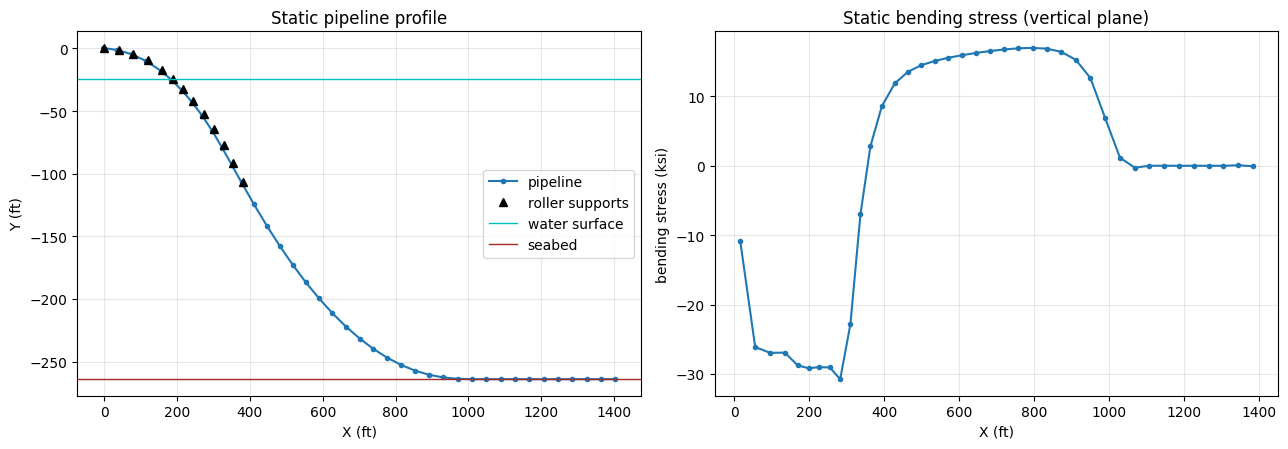

Tension at tensioner / stinger tip / seabed (kN): [177. 296. 262.]


In [8]:
def stress_MPa(x):      # bending stress from the change of node tangent angle per element length
    L = np.linalg.norm(np.diff(x[:, :2], axis=0), axis=1)
    return model.pipe.E*model.pipe.D_steel/2*np.diff(x[:, 5])/L/1e6

fig, ax = plt.subplots(1, 2, figsize=(13, 4.6))
X = x_static
ax[0].plot(X[:, 0]/FT, X[:, 1]/FT, '-o', ms=3, label='pipeline')
sx = [model.supports[i][0] for i in model.supports]; sy = [model.supports[i][1] for i in model.supports]
ax[0].plot(np.array(sx)/FT, np.array(sy)/FT, 'k^', label='roller supports')
ax[0].axhline(model.y_water/FT, color='c', lw=1, label='water surface'); ax[0].axhline(model.y_bed/FT, color='brown', lw=1, label='seabed')
ax[0].set_xlabel('X (ft)'); ax[0].set_ylabel('Y (ft)'); ax[0].set_title('Static pipeline profile'); ax[0].legend(); ax[0].grid(alpha=.3)
mid = 0.5*(X[1:, 0]+X[:-1, 0])/FT
ax[1].plot(mid, stress_MPa(X)*0.145038, '-o', ms=3); ax[1].set_xlabel('X (ft)'); ax[1].set_ylabel('bending stress (ksi)')
ax[1].set_title('Static bending stress (vertical plane)'); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()
print("Tension at tensioner / stinger tip / seabed (kN):", (model.tensions(X)[[0, tip, -2]]/1e3).round(0))

## Checks on the 3-D model

(i) In a symmetric vertical-plane case the 3-D solution must reduce to the planar one and the out-of-plane DOF (Z, ψ, α) must stay zero; (ii) an in-plane barge motion (surge, heave, pitch) applied to the 3-D model must produce no out-of-plane response.

In [9]:
planar = build(K_t=0.0, K_roll=2e7, planar=True)
xp_static, okp, _ = planar.newton(planar.X0)
print("static: max |3-D - planar| over X, Y, beta :", np.abs(x_static-xp_static)[:, [0, 1, 5]].max(), " m/rad")
print("static: max |Z|, |psi|, |alpha| in 3-D     :", np.abs(x_static[:, [2, 3, 4]]).max(axis=0))
chk = integrate(model, x_static, 6.0, motion=barge_motion_planar)
print("in-plane barge motion, 3-D model, 6 s: max |Z|, |psi|, |alpha| =", np.abs(chk['x'][:, :, [2, 3, 4]]).max(axis=(0, 1)), " (must be ~0)")

static: max |3-D - planar| over X, Y, beta : 1.4210854715202004e-14  m/rad
static: max |Z|, |psi|, |alpha| in 3-D     : [0. 0. 0.]
in-plane barge motion, 3-D model, 6 s: max |Z|, |psi|, |alpha| = [0. 0. 0.]  (must be ~0)


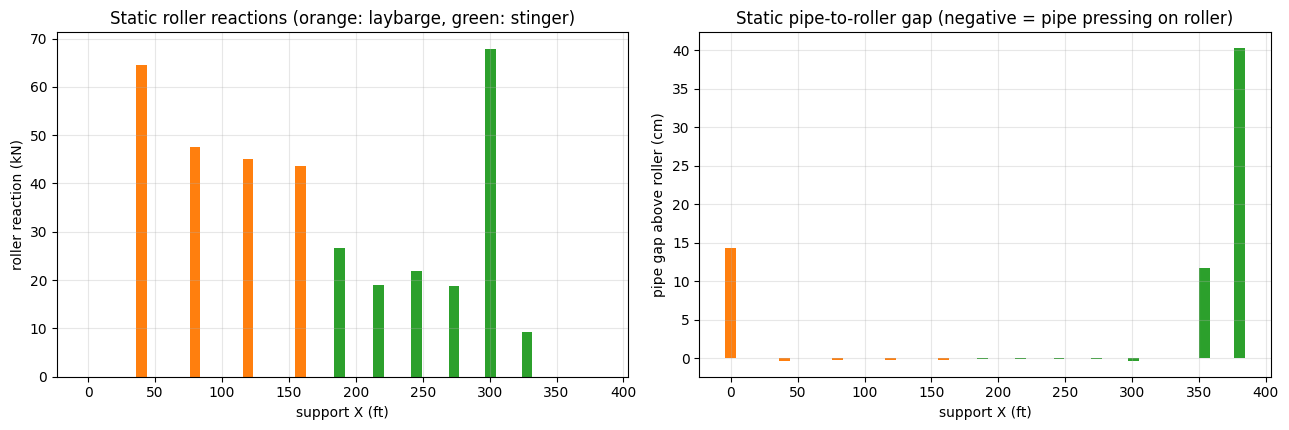

Stinger tip roller (support 12): reaction 0.0 kN, gap 40.3 cm
Largest static roller reaction: 67.9 kN at support 9


In [10]:
def roller_reaction(x, off=(0., 0.)):
    """Normal roller reactions (N) and pipe-to-support gaps (m) at all support nodes (same contact law as Model.node_loads)."""
    st = model.roller_state(x, off)
    return {i: v[0] for i, v in st.items()}, {i: v[1] for i, v in st.items()}

sup_ids = sorted(model.supports); tip_id = sup_ids[-1]
R0, gap0 = roller_reaction(x_static)
xs = np.array([model.supports[i][0] for i in sup_ids])/FT
fig, ax = plt.subplots(1, 2, figsize=(13, 4.4))
cols = ['tab:orange' if i <= 4 else 'tab:green' for i in sup_ids]
ax[0].bar(xs, [R0[i]/1e3 for i in sup_ids], width=8, color=cols)
ax[0].set_xlabel('support X (ft)'); ax[0].set_ylabel('roller reaction (kN)'); ax[0].grid(alpha=.3)
ax[0].set_title('Static roller reactions (orange: laybarge, green: stinger)')
ax[1].bar(xs, [gap0[i]*100 for i in sup_ids], width=8, color=cols)
ax[1].set_xlabel('support X (ft)'); ax[1].set_ylabel('pipe gap above roller (cm)'); ax[1].grid(alpha=.3)
ax[1].set_title('Static pipe-to-roller gap (negative = pipe pressing on roller)')
plt.tight_layout(); plt.show()
print(f"Stinger tip roller (support {tip_id}): reaction {R0[tip_id]/1e3:.1f} kN, gap {gap0[tip_id]*100:.1f} cm")
print("Largest static roller reaction: %.1f kN at support %d" % (max(R0.values())/1e3, max(R0, key=R0.get)))

## Dynamic solution

30 s (3 wave periods) with h = 0.1 s and damping ratio 0.55, all six barge motions applied. Takes about 2–3 minutes.

In [11]:
import time; t0 = time.time()
hist = integrate(model, x_static, 30.0, h=0.1, damping_ratio=0.55)
print(f"{len(hist['t'])-1} steps in {time.time()-t0:.0f} s; max Newton iterations per step: {max(hist['iters'])}")

300 steps in 138 s; max Newton iterations per step: 8


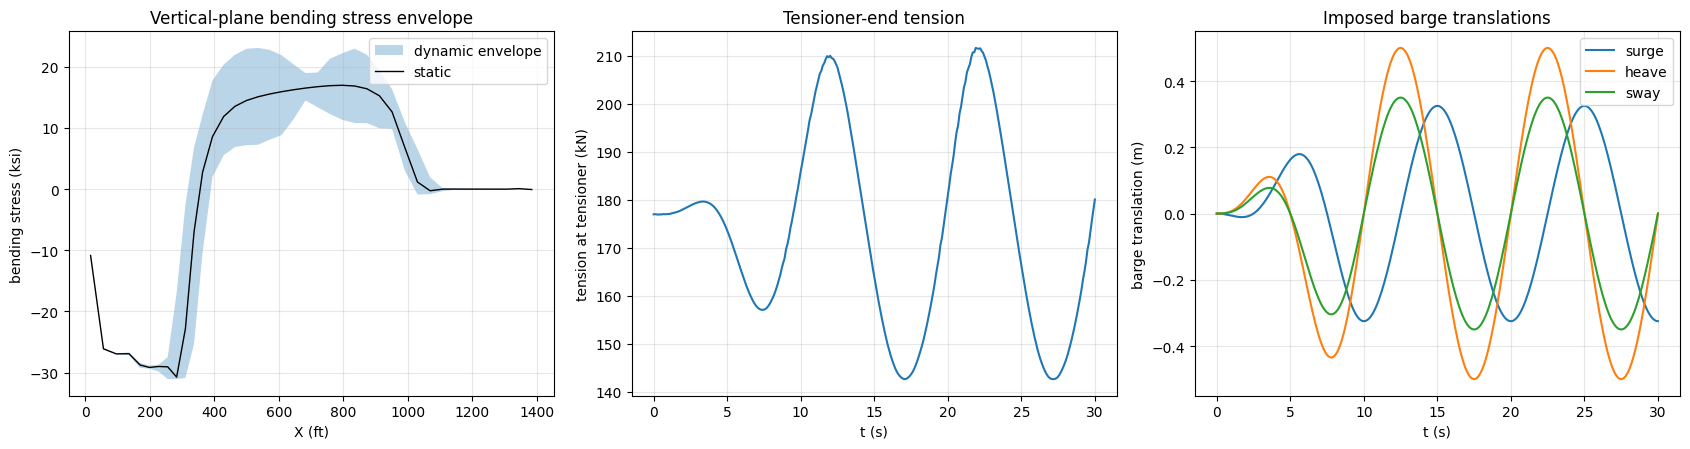

largest dynamic stress range: 222 MPa at X = 337 ft; static stress there -48 MPa
tension at tensioner: 143 .. 212 kN (nominal 178)


In [12]:
t, XH = hist['t'], hist['x']
S = np.array([stress_MPa(xx) for xx in XH]); sel = t > 10          # skip the start-up ramp
smax, smin = S[sel].max(0), S[sel].min(0)
Tt = np.array([model.tensions(xx)[0] for xx in XH])

fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
ax[0].fill_between(mid, smin*0.145038, smax*0.145038, alpha=.3, label='dynamic envelope')
ax[0].plot(mid, stress_MPa(x_static)*0.145038, 'k-', lw=1, label='static'); ax[0].set_xlabel('X (ft)'); ax[0].set_ylabel('bending stress (ksi)')
ax[0].set_title('Vertical-plane bending stress envelope'); ax[0].legend(); ax[0].grid(alpha=.3)
ax[1].plot(t, Tt/1e3); ax[1].set_xlabel('t (s)'); ax[1].set_ylabel('tension at tensioner (kN)'); ax[1].set_title('Tensioner-end tension'); ax[1].grid(alpha=.3)
off = np.array([barge_motion(tt) for tt in t])
for k, nm in enumerate(['surge', 'heave', 'sway']): ax[2].plot(t, off[:, k], label=nm)
ax[2].set_xlabel('t (s)'); ax[2].set_ylabel('barge translation (m)'); ax[2].set_title('Imposed barge translations'); ax[2].legend(); ax[2].grid(alpha=.3)
plt.tight_layout(); plt.show()
k = np.argmax(smax-smin)
print(f"largest dynamic stress range: {(smax-smin)[k]:.0f} MPa at X = {mid[k]:.0f} ft; static stress there {stress_MPa(x_static)[k]:.0f} MPa")
print(f"tension at tensioner: {Tt[sel].min()/1e3:.0f} .. {Tt[sel].max()/1e3:.0f} kN (nominal {model.T0/1e3:.0f})")

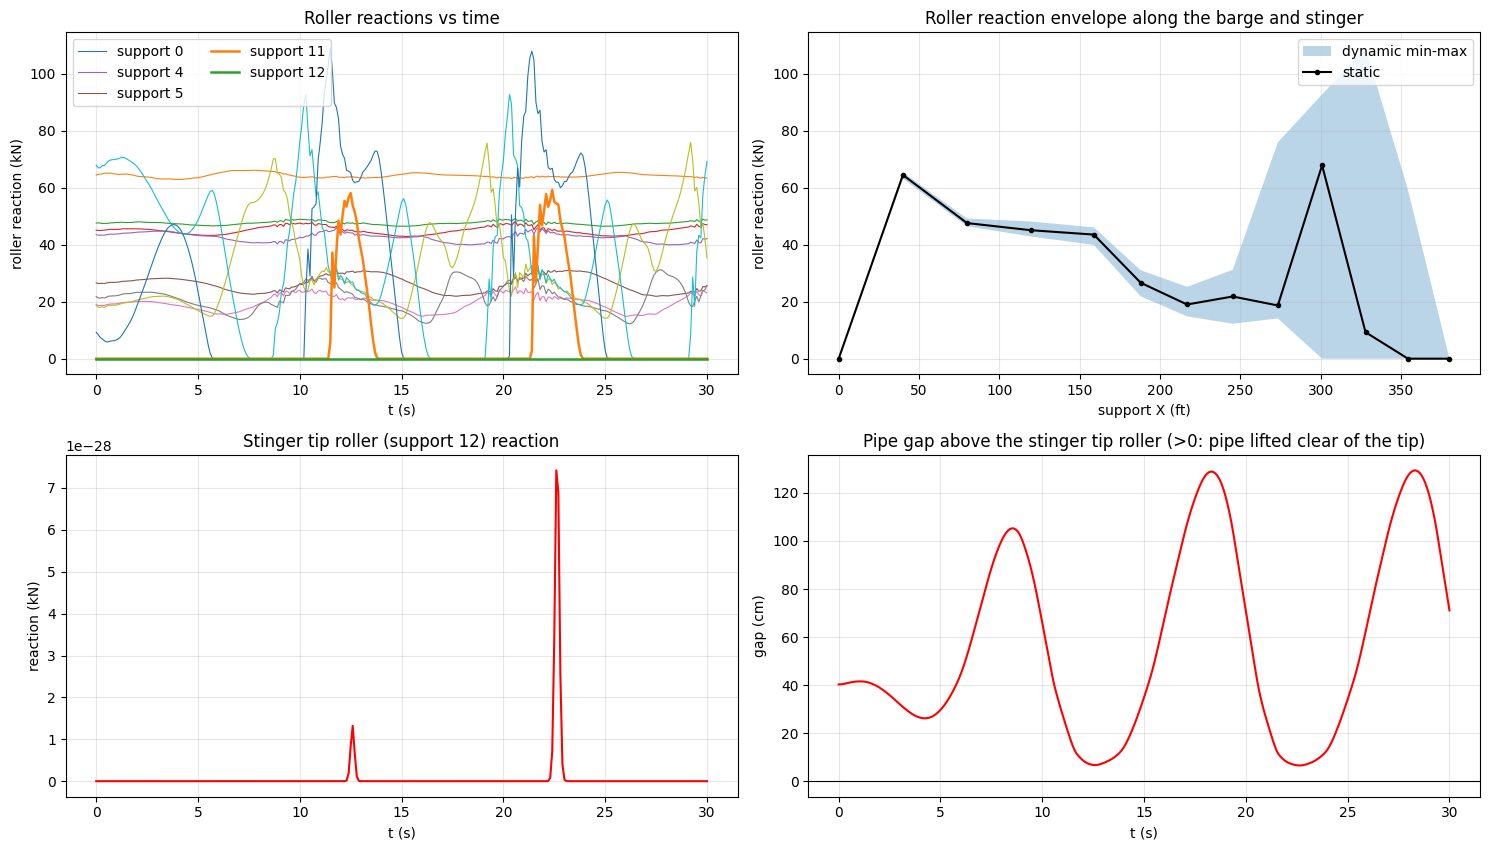

Stinger tip roller: reaction 0.0 .. 0.0 kN, gap 6.5 .. 129.4 cm
Largest dynamic roller reaction: 109.1 kN at support 10


In [13]:
RT = {i: np.zeros(len(t)) for i in sup_ids}; GT = {i: np.zeros(len(t)) for i in sup_ids}
for k, (tt, xx) in enumerate(zip(t, XH)):
    Rk, Gk = roller_reaction(xx, barge_motion(tt))
    for i in sup_ids: RT[i][k] = Rk[i]; GT[i][k] = Gk[i]

fig, ax = plt.subplots(2, 2, figsize=(15, 8.6))
for i in sup_ids:
    ax[0, 0].plot(t, RT[i]/1e3, lw=1.8 if i in (tip_id, tip_id-1) else 0.8, label=f'support {i}' if i in (0, 4, 5, tip_id-1, tip_id) else None)
ax[0, 0].set_xlabel('t (s)'); ax[0, 0].set_ylabel('roller reaction (kN)'); ax[0, 0].set_title('Roller reactions vs time'); ax[0, 0].legend(ncol=2); ax[0, 0].grid(alpha=.3)
rmax = [RT[i][sel].max()/1e3 for i in sup_ids]; rmin = [RT[i][sel].min()/1e3 for i in sup_ids]
ax[0, 1].fill_between(xs, rmin, rmax, alpha=.3, label='dynamic min-max'); ax[0, 1].plot(xs, [R0[i]/1e3 for i in sup_ids], 'k-o', ms=3, label='static')
ax[0, 1].set_xlabel('support X (ft)'); ax[0, 1].set_ylabel('roller reaction (kN)'); ax[0, 1].set_title('Roller reaction envelope along the barge and stinger'); ax[0, 1].legend(); ax[0, 1].grid(alpha=.3)
ax[1, 0].plot(t, RT[tip_id]/1e3, 'r'); ax[1, 0].set_xlabel('t (s)'); ax[1, 0].set_ylabel('reaction (kN)'); ax[1, 0].set_title(f'Stinger tip roller (support {tip_id}) reaction'); ax[1, 0].grid(alpha=.3)
ax[1, 1].plot(t, GT[tip_id]*100, 'r'); ax[1, 1].axhline(0, color='k', lw=.8)
ax[1, 1].set_xlabel('t (s)'); ax[1, 1].set_ylabel('gap (cm)'); ax[1, 1].set_title('Pipe gap above the stinger tip roller (>0: pipe lifted clear of the tip)'); ax[1, 1].grid(alpha=.3)
plt.tight_layout(); plt.show()
print(f"Stinger tip roller: reaction {RT[tip_id][sel].min()/1e3:.1f} .. {RT[tip_id][sel].max()/1e3:.1f} kN, gap {GT[tip_id][sel].min()*100:.1f} .. {GT[tip_id][sel].max()*100:.1f} cm")
print("Largest dynamic roller reaction: %.1f kN at support %d" % (max(RT[i][sel].max() for i in sup_ids)/1e3, max(sup_ids, key=lambda i: RT[i][sel].max())))

## 3-D response: lateral motion, twist, combined bending

The new out-of-plane results: plan view of the pipeline, lateral displacement and twist, barge rotations, and the combined (vertical + lateral) bending stress.

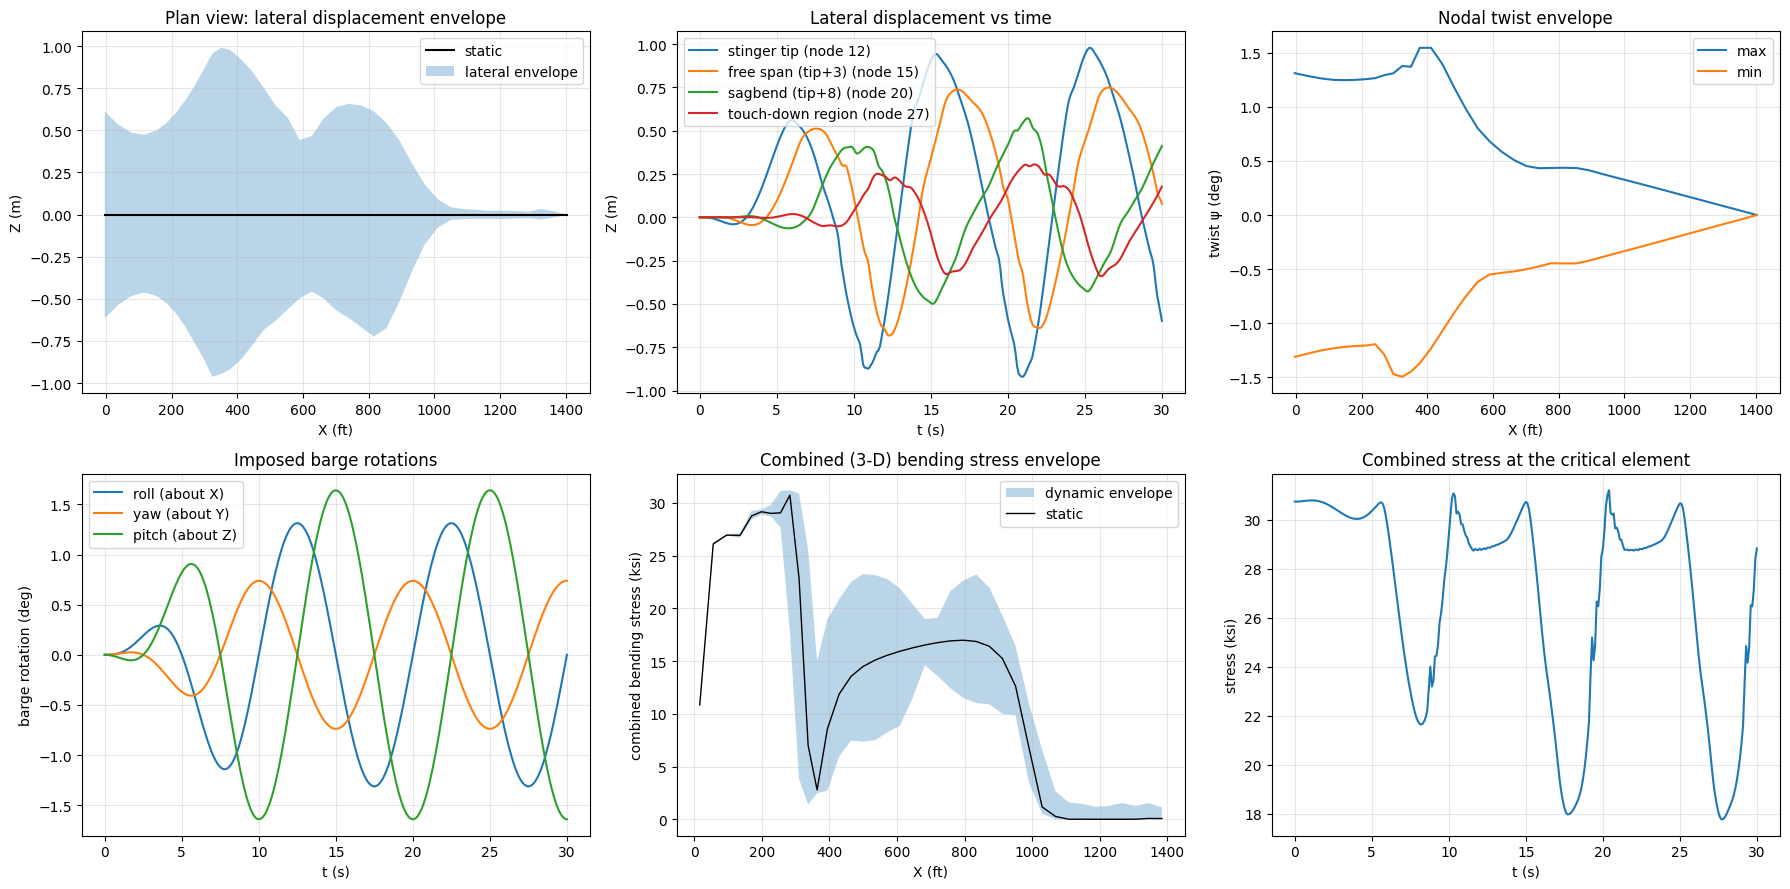

max lateral displacement: 0.99 m at node 11;  max twist 1.57 deg
peak combined bending stress: 215 MPa (31.2 ksi) at X = 283 ft  (static there: 212 MPa)


In [14]:
def combined_stress_MPa(x):
    """Resultant bending stress from the change of node tangent direction per element length (vertical + lateral curvature)."""
    tx = np.array([node_axes(*xi[3:6])[:, 0] for xi in x])
    elev = np.arcsin(np.clip(tx[:, 1], -1, 1)); head = np.arctan2(tx[:, 2], tx[:, 0])
    L = np.linalg.norm(np.diff(x[:, :3], axis=0), axis=1)
    kv = np.diff(elev)/L; kh = np.diff(head)*np.cos(0.5*(elev[1:]+elev[:-1]))/L
    return model.pipe.E*model.pipe.D_steel/2*np.hypot(kv, kh)/1e6

Cs = np.array([combined_stress_MPa(xx) for xx in XH]); C_static = combined_stress_MPa(x_static)
Z = XH[:, :, 2]; node_ids = {'stinger tip': tip, 'free span (tip+3)': tip+3, 'sagbend (tip+8)': tip+8, 'touch-down region': td}

fig, ax = plt.subplots(2, 3, figsize=(18, 9))
ax[0, 0].plot(x_static[:, 0]/FT, x_static[:, 2], 'k-', lw=1.5, label='static')
ax[0, 0].fill_between(x_static[:, 0]/FT, Z[sel].min(0), Z[sel].max(0), alpha=.3, label='lateral envelope')
ax[0, 0].set_xlabel('X (ft)'); ax[0, 0].set_ylabel('Z (m)'); ax[0, 0].set_title('Plan view: lateral displacement envelope'); ax[0, 0].legend(); ax[0, 0].grid(alpha=.3)
for nm, i in node_ids.items(): ax[0, 1].plot(t, Z[:, i], label=f'{nm} (node {i})')
ax[0, 1].set_xlabel('t (s)'); ax[0, 1].set_ylabel('Z (m)'); ax[0, 1].set_title('Lateral displacement vs time'); ax[0, 1].legend(); ax[0, 1].grid(alpha=.3)
ax[0, 2].plot(x_static[:, 0]/FT, np.degrees(XH[sel][:, :, 3]).max(0), label='max'); ax[0, 2].plot(x_static[:, 0]/FT, np.degrees(XH[sel][:, :, 3]).min(0), label='min')
ax[0, 2].set_xlabel('X (ft)'); ax[0, 2].set_ylabel('twist ψ (deg)'); ax[0, 2].set_title('Nodal twist envelope'); ax[0, 2].legend(); ax[0, 2].grid(alpha=.3)
for k, nm in enumerate(['roll (about X)', 'yaw (about Y)', 'pitch (about Z)']): ax[1, 0].plot(t, np.degrees(off[:, 3+k]), label=nm)
ax[1, 0].set_xlabel('t (s)'); ax[1, 0].set_ylabel('barge rotation (deg)'); ax[1, 0].set_title('Imposed barge rotations'); ax[1, 0].legend(); ax[1, 0].grid(alpha=.3)
mid_ = 0.5*(x_static[1:, 0]+x_static[:-1, 0])/FT
ax[1, 1].fill_between(mid_, Cs[sel].min(0)*0.145038, Cs[sel].max(0)*0.145038, alpha=.3, label='dynamic envelope')
ax[1, 1].plot(mid_, C_static*0.145038, 'k-', lw=1, label='static'); ax[1, 1].set_xlabel('X (ft)'); ax[1, 1].set_ylabel('combined bending stress (ksi)')
ax[1, 1].set_title('Combined (3-D) bending stress envelope'); ax[1, 1].legend(); ax[1, 1].grid(alpha=.3)
ax[1, 2].plot(t, Cs[:, np.argmax(Cs[sel].max(0))]*0.145038); ax[1, 2].set_xlabel('t (s)'); ax[1, 2].set_ylabel('stress (ksi)')
ax[1, 2].set_title('Combined stress at the critical element'); ax[1, 2].grid(alpha=.3)
plt.tight_layout(); plt.show()
kc = np.argmax(Cs[sel].max(0))
print(f"max lateral displacement: {np.abs(Z).max():.2f} m at node {np.abs(Z).max(0).argmax()};  max twist {np.degrees(np.abs(XH[:, :, 3]).max()):.2f} deg")
print(f"peak combined bending stress: {Cs[sel].max():.0f} MPa ({Cs[sel].max()*0.145038:.1f} ksi) at X = {mid_[kc]:.0f} ft  (static there: {C_static[kc]:.0f} MPa)")

## Notes
* **Extending it:** (a) flexible stinger = more `pipe_element`s with nonzero undeformed node rotations; (b) steady current / lateral loads: add a current velocity to the drag term in `pipe_element`; (c) analytic tangent: replace `Model.jacobian`.
* **Checks run while building this:** at-rest drift of the dynamic solver ≈ 1e-10 m; the 3-D model reproduces the planar static solution and keeps in-plane barge motions in-plane (see the check cell); each of sway, roll, yaw, pitch and surge+heave was run on its own and is stable (≤ 8 Newton iterations/step); end forces follow `f = −∂U/∂q` including the beam-column terms. A sign error in the Euler heading rate (Eq. 2-31: α is a rotation about −Y) had made all out-of-plane runs diverge; with it fixed they are stable.
* **Lateral results are the least validated part:** the thesis' own example is planar-dominated, and the barge phases, guide and soil stiffnesses are my assumptions.
* **Comparison with the thesis (§5.2):** only roughly matched. The thesis reports lift-off ≈ 81 ft below the surface, departure angle ≈ 32.5° and a suspended span ≈ 450 ft; this model lifts off earlier (≈ 55 ft, last loaded support 10 of 12), leaves the tip at ≈ 27° and touches down ≈ 550 ft out. The rigid stinger, the assumed deck height and the clamped seabed end (which fixes the bottom tension) are the likely causes. I have not tuned anything to force agreement.